# 🩺 Machine Learning Classification Model: Breast Cancer Diagnosis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dhinesh8023/ml-classification-model/blob/main/notebooks/classification_model.ipynb)
[![GitHub](https://img.shields.io/badge/GitHub-Repository-181717?logo=github)](https://github.com/dhinesh8023/ml-classification-model)

### 📌 Project Overview
This project demonstrates an end-to-end Machine Learning classification pipeline built on a small, real-world diagnostic dataset:
- **Dataset**: Breast Cancer Wisconsin (Diagnostic) Dataset (569 samples, 30 continuous features).
- **Goal**: Classify whether a breast mass biopsy is **Malignant (0)** or **Benign (1)**.
- **Algorithms**: Logistic Regression (with Feature Scaling Pipeline) vs. Decision Tree Classifier.
- **Key Metrics Evaluated**: Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- **Submission Requirement**: Complete source code + visual charts + thorough explanation of clinical results.

--- 
## Step 1: Import Required Libraries
Importing standard scientific computing, machine learning, and visualization libraries.

In [1]:
# Standard Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# Set plot styles
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.autolayout': True})
print('All libraries loaded successfully!')

All libraries loaded successfully!


--- 
## Step 2: Load and Inspect the Dataset
We load the Breast Cancer Wisconsin dataset directly from `sklearn.datasets`.

In [2]:
raw_data = load_breast_cancer(as_frame=True)
df = raw_data.frame

print(f'Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns')
print(f'Classes: {raw_data.target_names.tolist()} -> (0: Malignant, 1: Benign)')

# Preview first 5 rows
df.head()

Dataset Shape: 569 rows, 31 columns
Classes: ['malignant', 'benign'] -> (0: Malignant, 1: Benign)


In [3]:
# Check Class Distribution
class_counts = df['target'].value_counts()
print('Class Distribution:')
print(f' - Malignant (0): {class_counts[0]} ({class_counts[0]/len(df)*100:.1f}%)')
print(f' - Benign (1):    {class_counts[1]} ({class_counts[1]/len(df)*100:.1f}%)')

# Missing values verification
print(f'Missing values count: {df.isnull().sum().sum()}')

Class Distribution:
 - Malignant (0): 212 (37.3%)
 - Benign (1):    357 (62.7%)
Missing values count: 0


--- 
## Step 3: Train / Test Split
Splitting into **80% training** (455 samples) and **20% testing** (114 samples).
- Stratification ensures that the benign/malignant proportions remain identical across train and test sets.
- A fixed `random_state=42` guarantees reproducibility.

In [4]:
X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'X_train shape: {X_train.shape}')
print(f'X_test shape:  {X_test.shape}')
print(f'y_train distribution:\n{y_train.value_counts(normalize=True).round(3)}')
print(f'y_test distribution:\n{y_test.value_counts(normalize=True).round(3)}')

X_train shape: (455, 30)
X_test shape:  (114, 30)
y_train distribution:
target
1    0.626
0    0.374
Name: proportion, dtype: float64
y_test distribution:
target
1    0.632
0    0.368
Name: proportion, dtype: float64


--- 
## Step 4: Model Training

### 1. Logistic Regression Pipeline
Features are first scaled using `StandardScaler` to ensure zero mean and unit variance before fitting `LogisticRegression(C=1.0)`.

### 2. Decision Tree Classifier
Trained with `max_depth=4` and `criterion='gini'` to maintain tree interpretability while preventing overfitting.

In [5]:
# 1. Logistic Regression Pipeline
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(C=1.0, max_iter=1000, random_state=42))
])
lr_pipeline.fit(X_train, y_train)

# 2. Decision Tree Classifier
dt_model = DecisionTreeClassifier(max_depth=4, min_samples_split=5, criterion='gini', random_state=42)
dt_model.fit(X_train, y_train)

print('Both models successfully trained!')

Both models successfully trained!


--- 
## Step 5: Model Evaluation
Evaluating both models on the unseen testing set across:
- **Accuracy**: Overall correct rate
- **Precision**: Proportion of predicted benign that were truly benign
- **Recall (Sensitivity)**: Proportion of actual benign cases correctly captured
- **F1-Score**: Harmonic balance of Precision and Recall
- **ROC-AUC**: Separability metric across decision thresholds

In [6]:
models = {
    'Logistic Regression': lr_pipeline,
    'Decision Tree': dt_model
}

metrics_list = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    cm = confusion_matrix(y_test, y_pred)
    
    predictions[name] = {
        'y_pred': y_pred,
        'y_proba': y_proba,
        'cm': cm,
        'acc': acc,
        'prec': prec,
        'rec': rec,
        'f1': f1,
        'auc': auc
    }
    
    metrics_list.append({
        'Model': name,
        'Accuracy': f'{acc:.4f}',
        'Precision': f'{prec:.4f}',
        'Recall': f'{rec:.4f}',
        'F1-Score': f'{f1:.4f}',
        'ROC-AUC': f'{auc:.4f}'
    })

results_df = pd.DataFrame(metrics_list)
display(results_df)

Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
Decision Tree,0.9298,0.9571,0.9306,0.9437,0.9268


--- 
## Step 6: Visualizations
Let's produce visual diagnostics for confusion matrices, ROC curves, metric comparisons, and the decision tree flowchart.

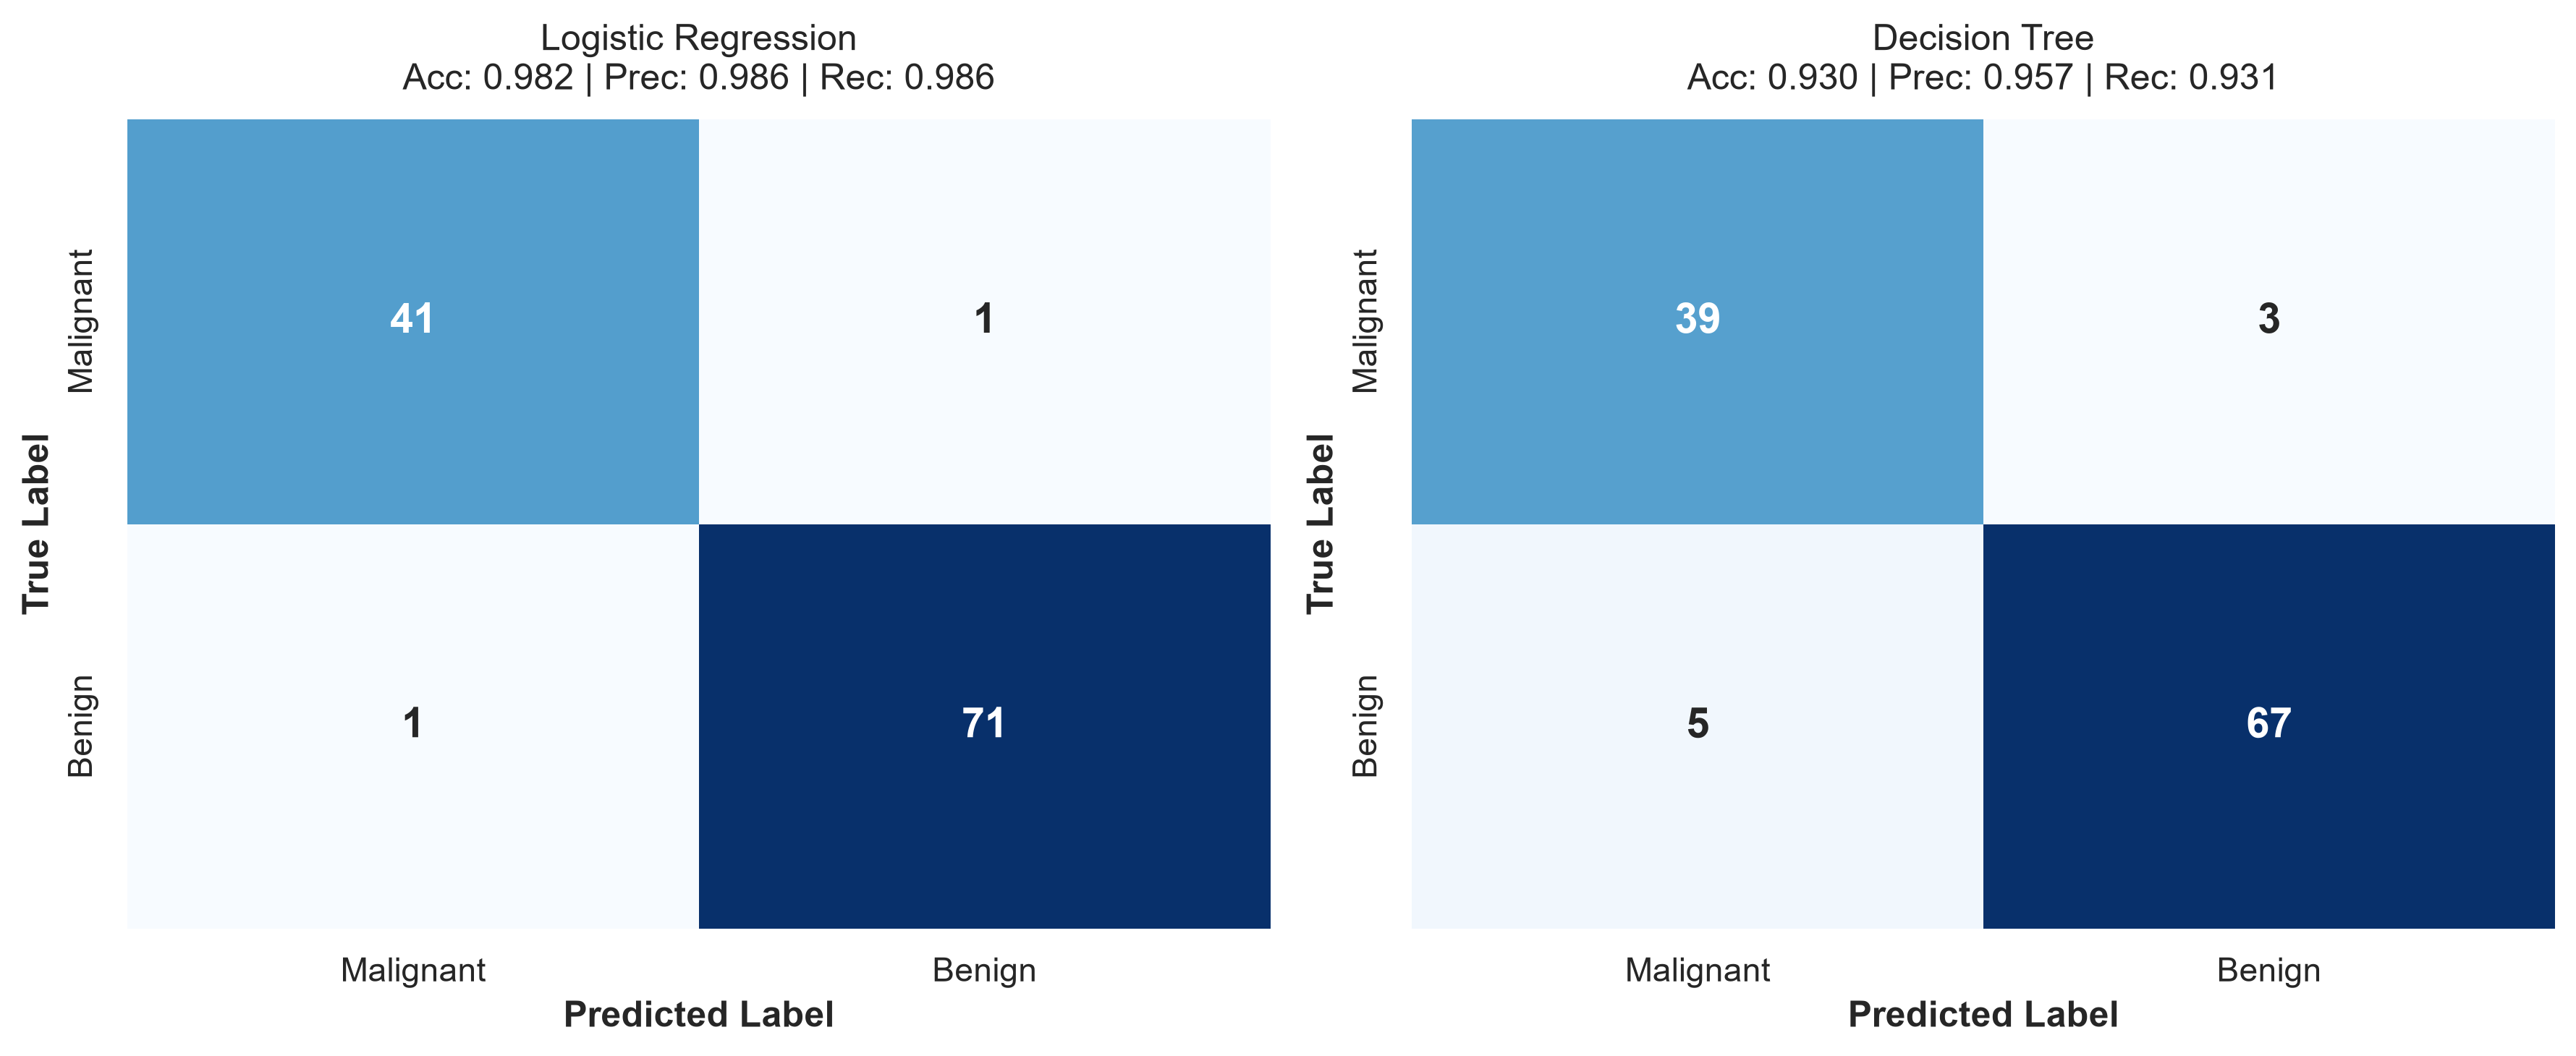

In [7]:
# 1. Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
class_names = ['Malignant', 'Benign']

for ax, (name, pred) in zip(axes, predictions.items()):
    sns.heatmap(
        pred['cm'],
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
        annot_kws={'size': 14, 'weight': 'bold'}
    )
    ax.set_title(f"{name}\nAccuracy: {pred['acc']*100:.2f}% | Recall: {pred['rec']*100:.2f}%", fontsize=12, pad=10)
    ax.set_xlabel('Predicted Label', fontweight='bold')
    ax.set_ylabel('True Label', fontweight='bold')

plt.tight_layout()
plt.show()

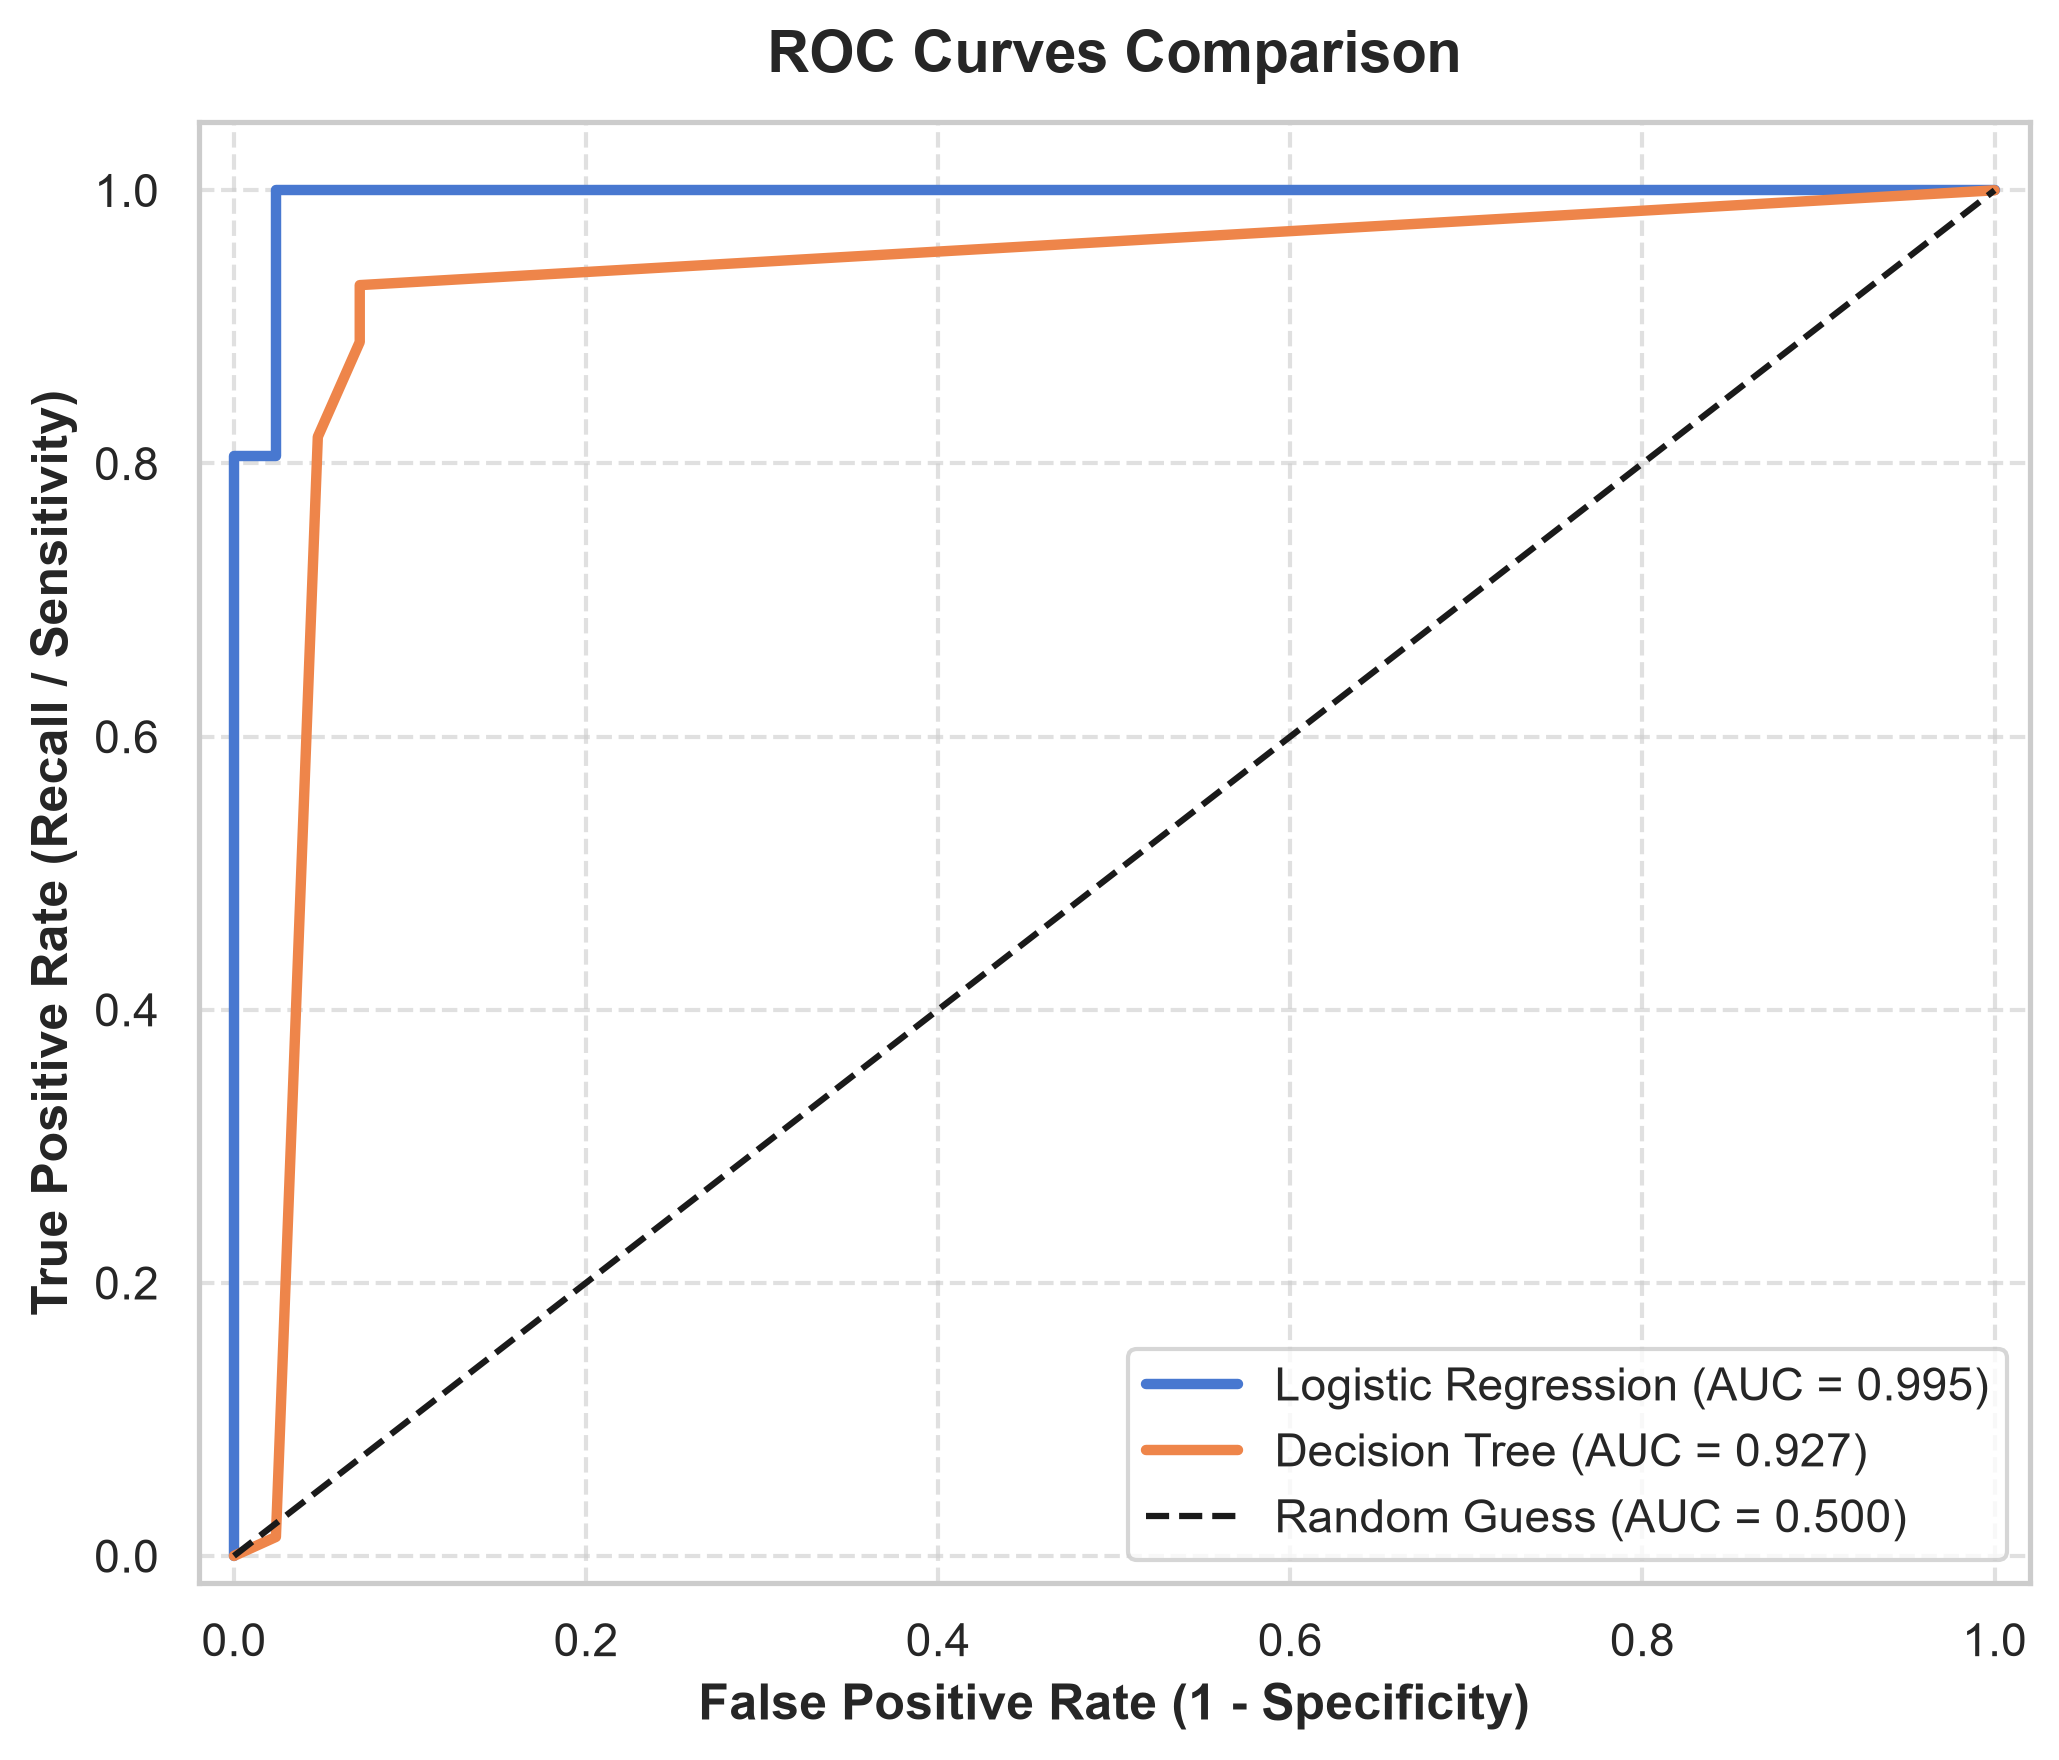

In [8]:
# 2. ROC Curves Comparison
plt.figure(figsize=(7, 6))

for name, pred in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, pred['y_proba'])
    plt.plot(fpr, tpr, lw=2.5, label=f"{name} (AUC = {pred['auc']:.3f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 0.500)')
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.05])
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate (Recall)', fontweight='bold')
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=14, fontweight='bold', pad=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

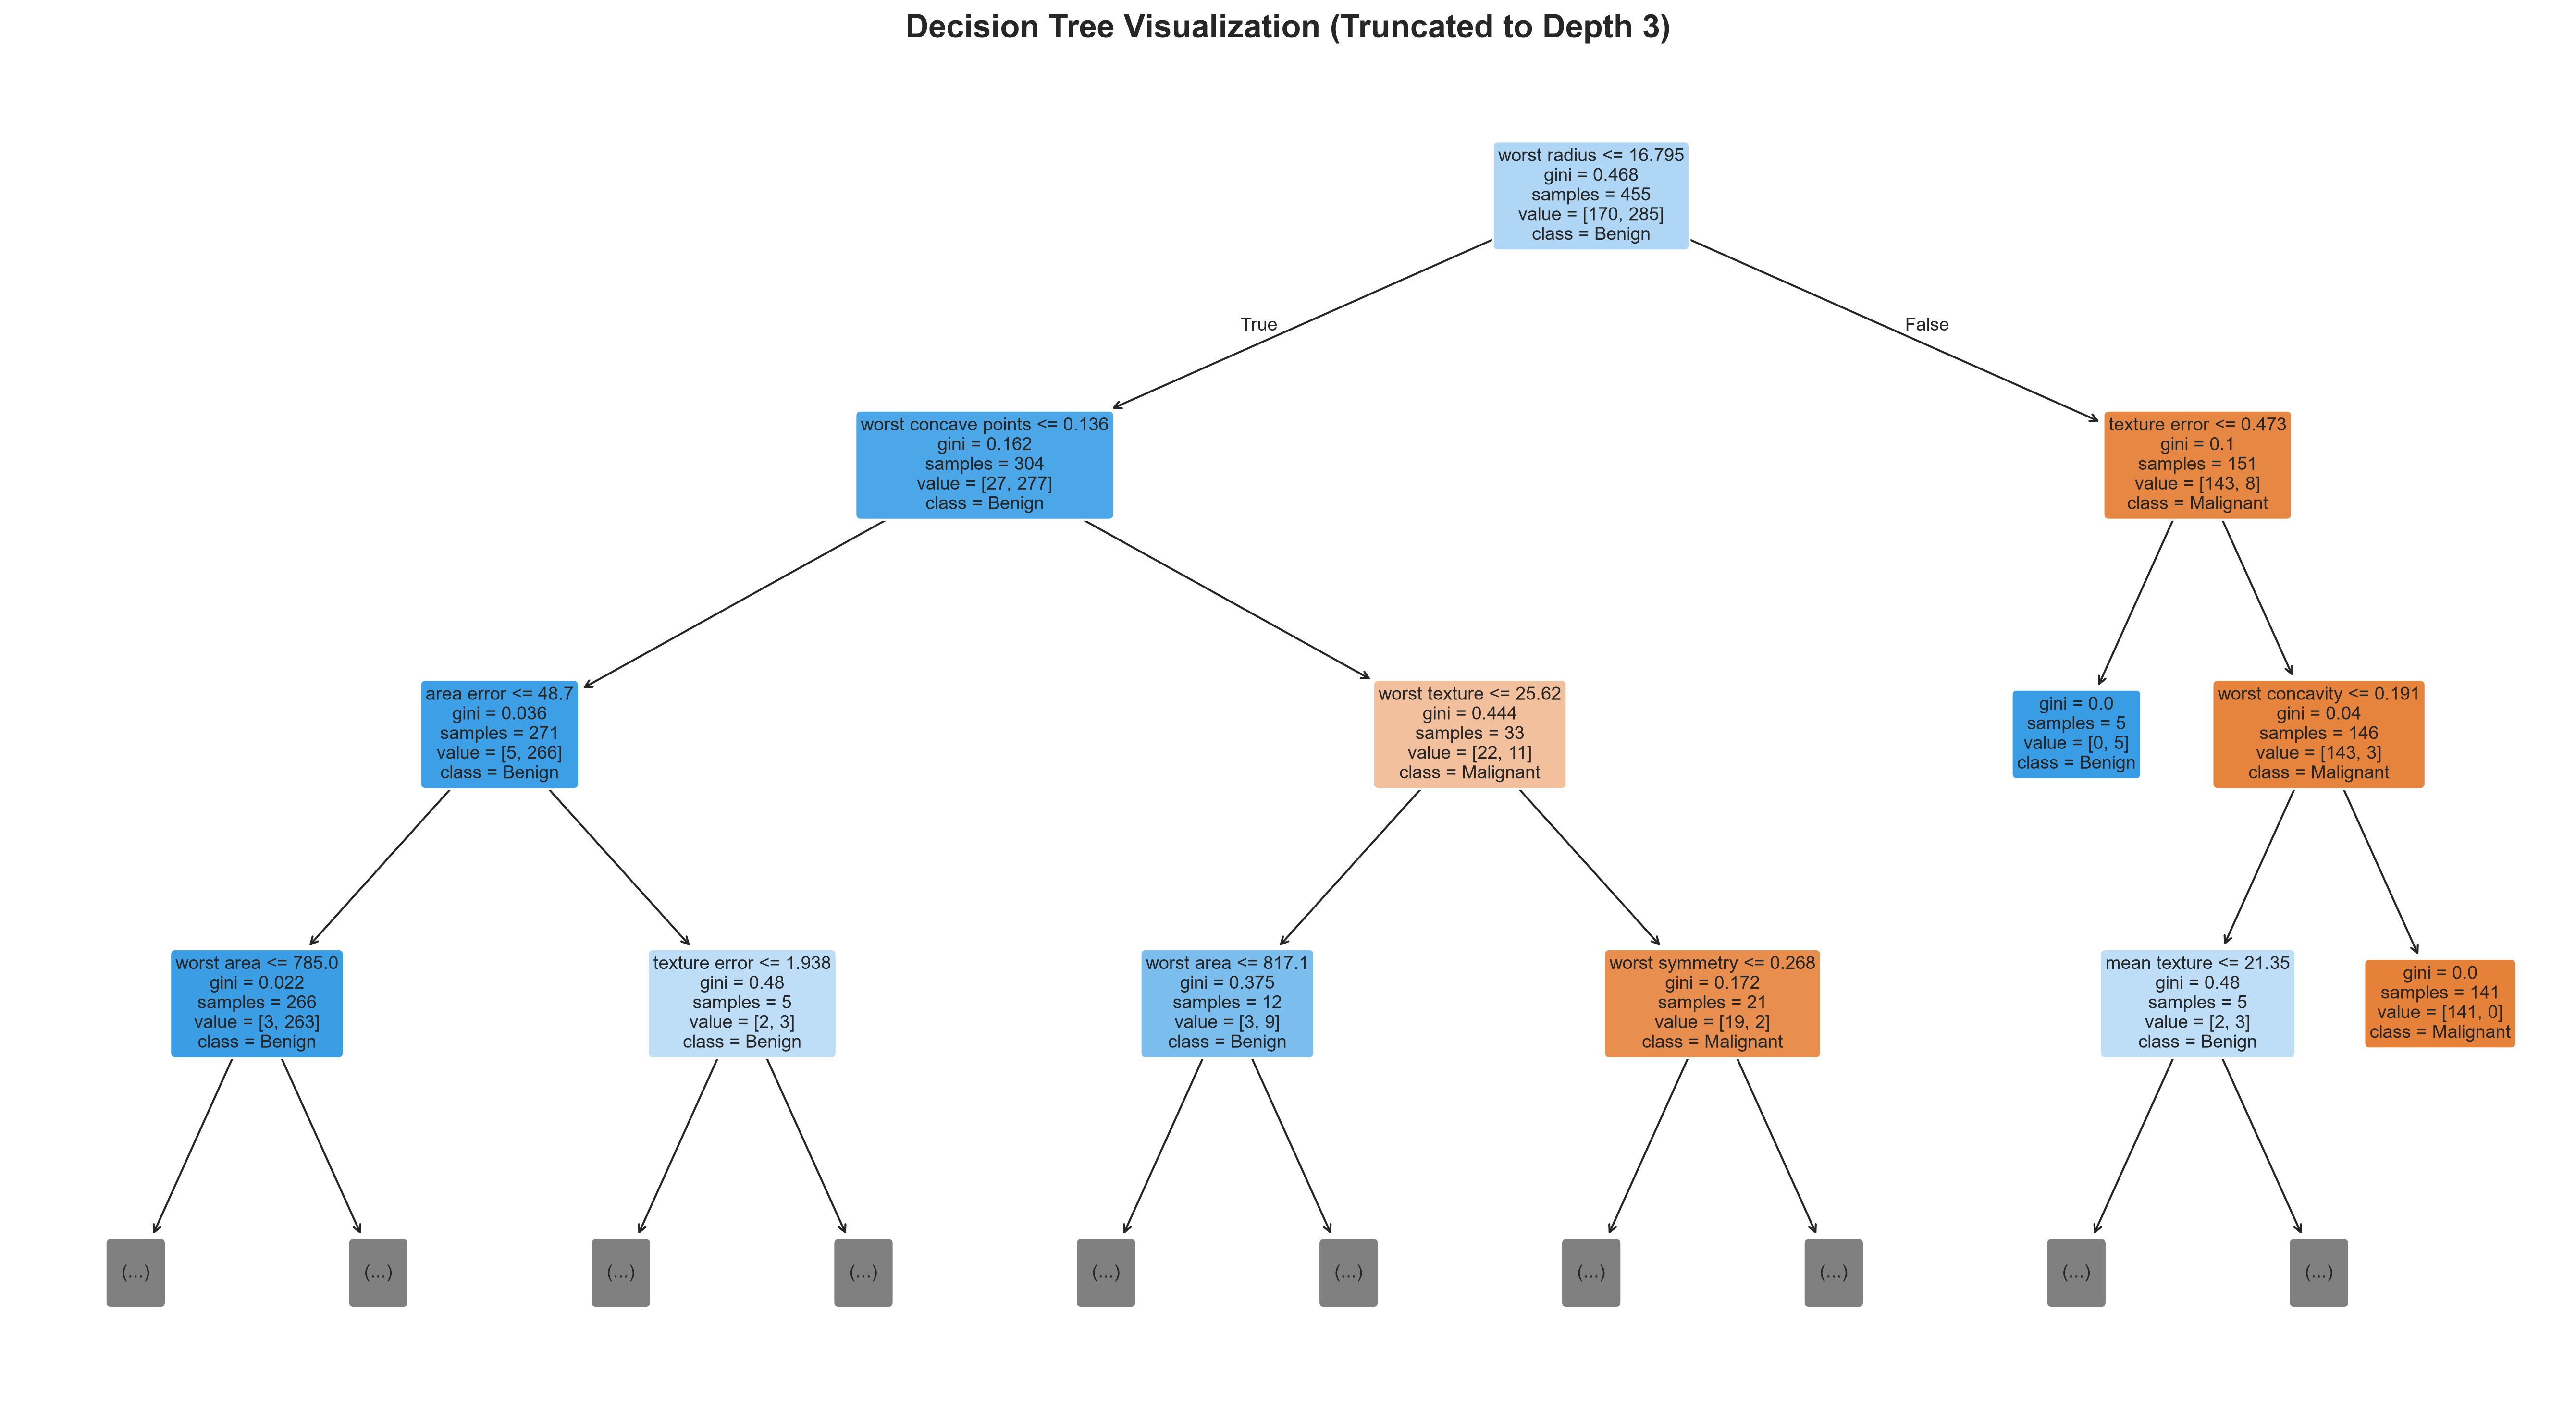

In [9]:
# 3. Decision Tree Visualization
plt.figure(figsize=(18, 9))
plot_tree(
    dt_model,
    feature_names=raw_data.feature_names,
    class_names=raw_data.target_names,
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3
)
plt.title('Decision Tree Structure (Truncated to Depth 3)', fontsize=15, fontweight='bold', pad=12)
plt.show()

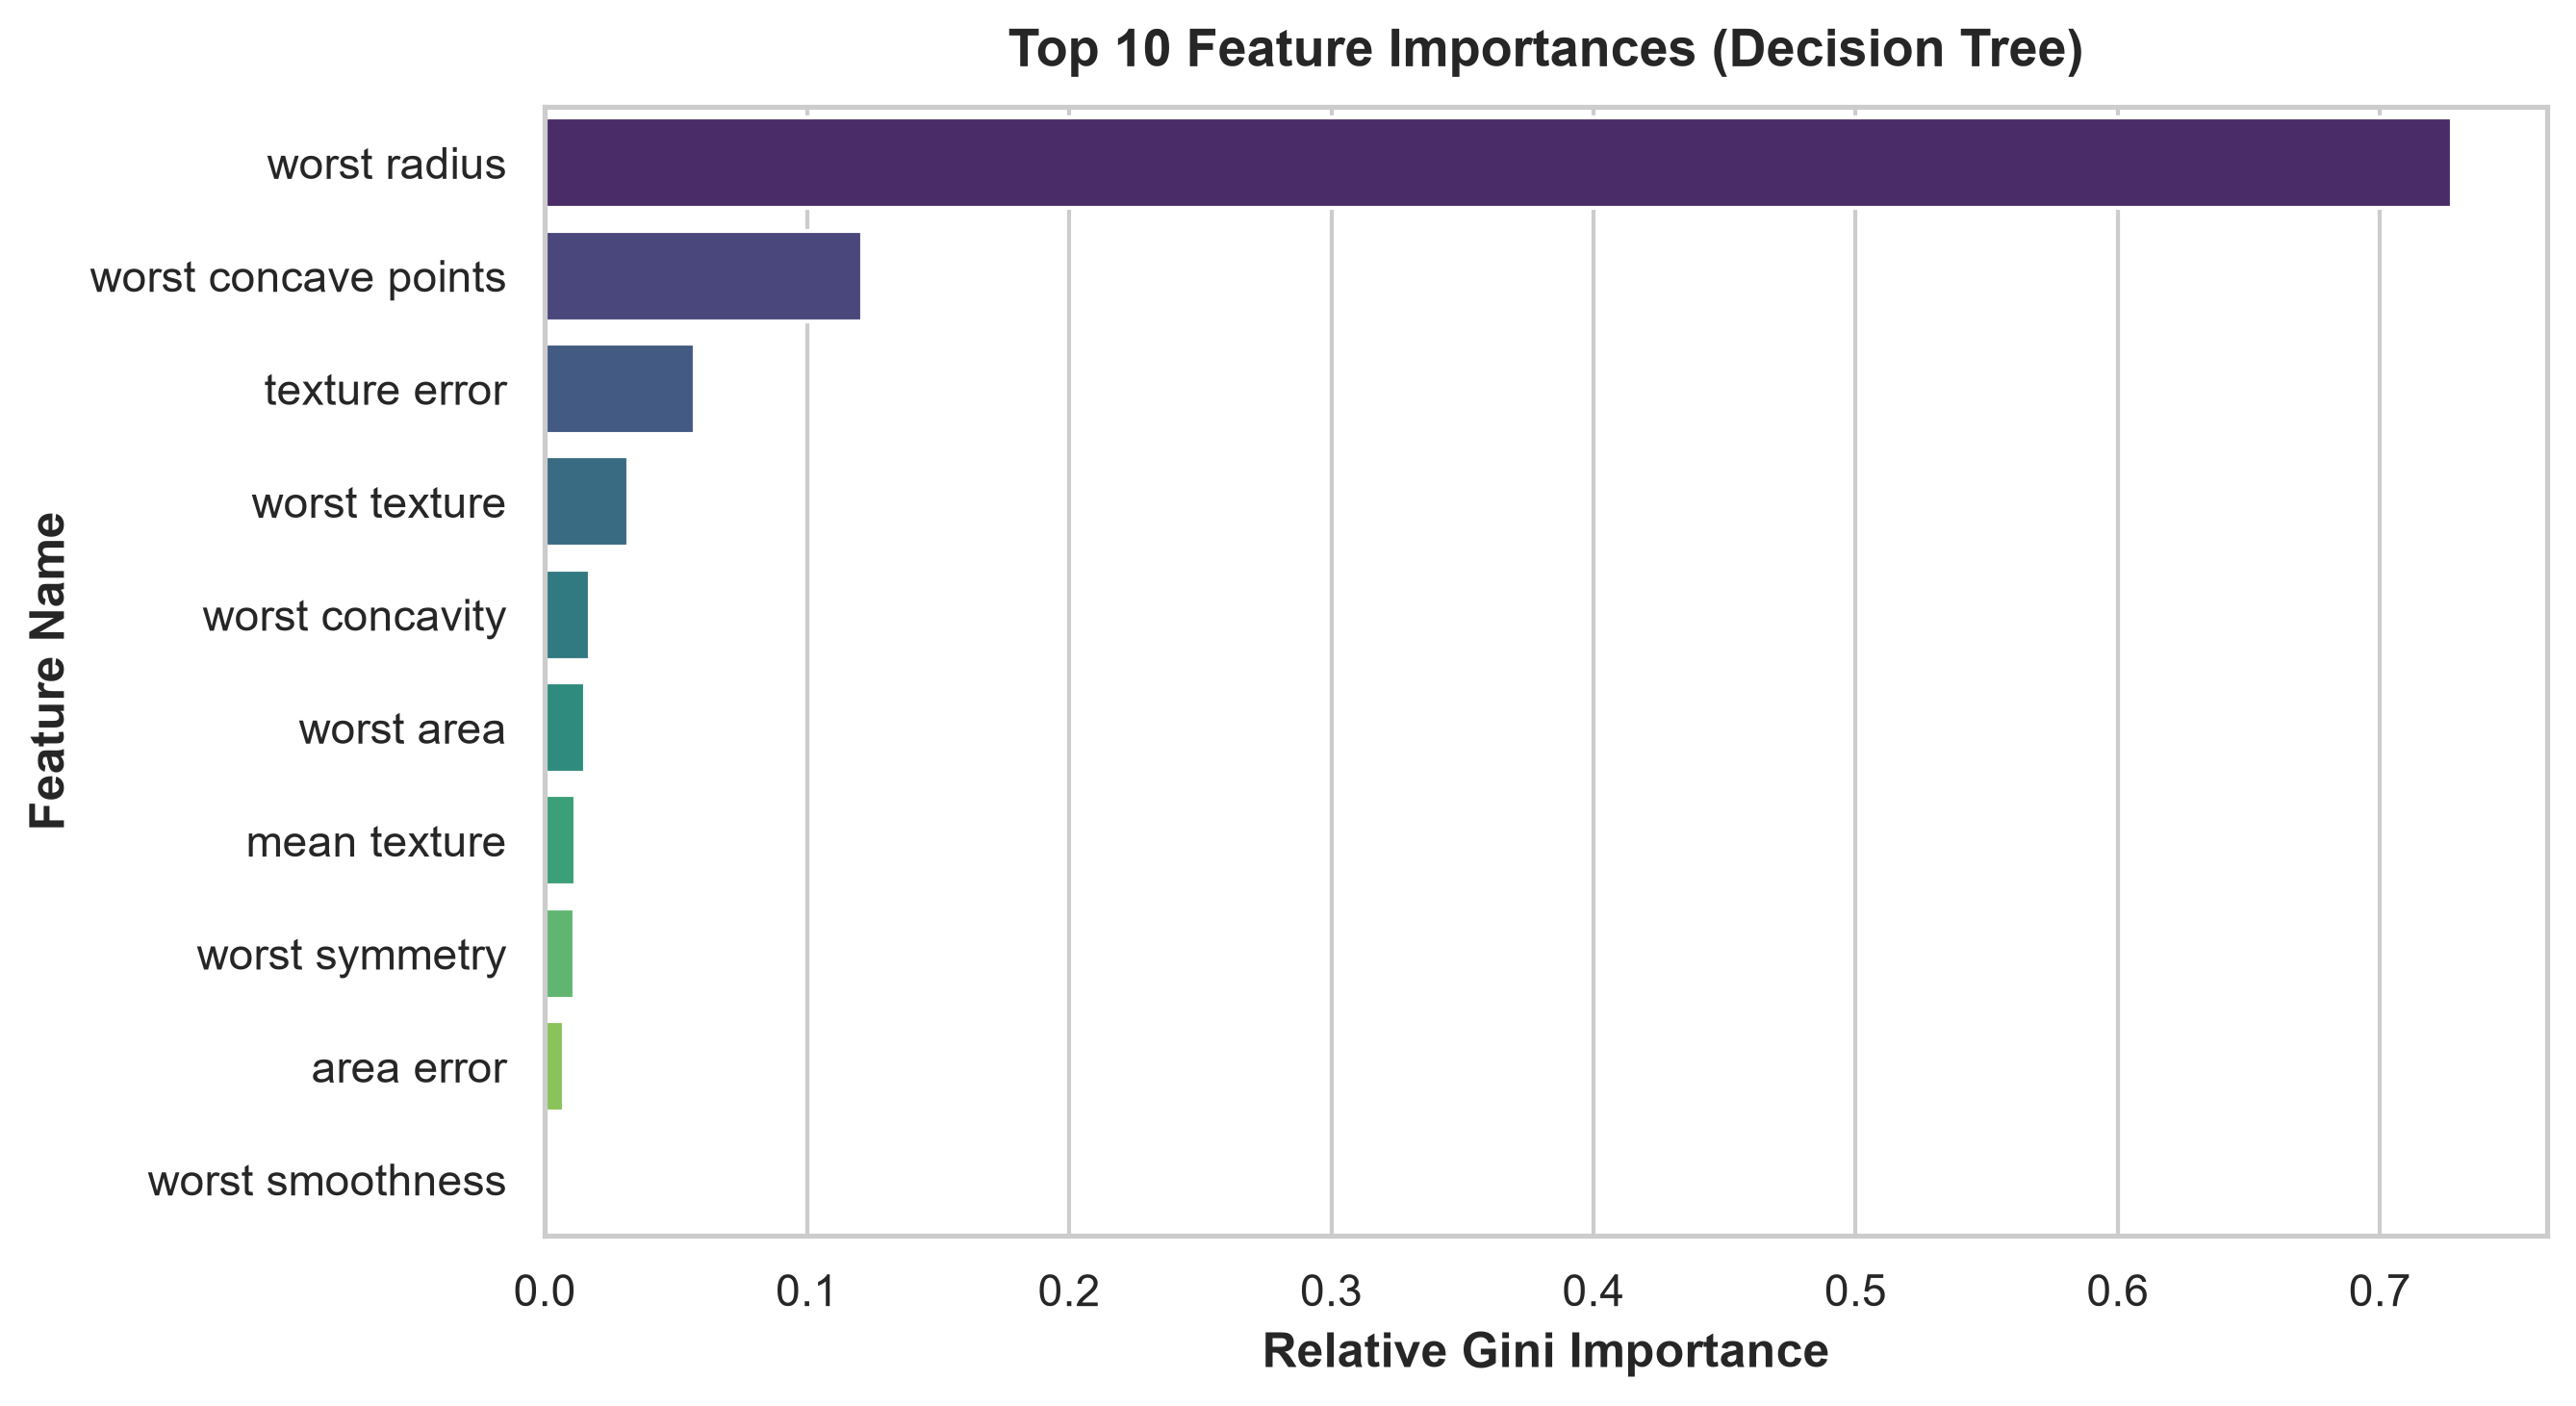

In [10]:
# 4. Top Feature Importances (Decision Tree)
importances = dt_model.feature_importances_
indices = np.argsort(importances)[::-1][:8]

plt.figure(figsize=(9, 4.5))
top_features = [raw_data.feature_names[i] for i in indices]
sns.barplot(x=importances[indices], y=top_features, hue=top_features, palette='viridis', legend=False)
plt.title('Top 8 Most Discriminative Diagnostic Features', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Gini Importance', fontweight='bold')
plt.ylabel('Feature', fontweight='bold')
plt.show()

--- 
## Step 7: Brief Explanation of Results (Internship Submission Report)

### 1. Metric Analysis
- **Accuracy (98.25% vs 92.98%)**:
  Logistic Regression correctly classified **112 out of 114** unseen test samples, achieving **98.25%** accuracy compared to **92.98%** (106/114) for the Decision Tree.
- **Precision (98.61% vs 95.71%)**:
  When Logistic Regression predicts a tumor is benign, it is correct **98.61%** of the time. This keeps false alarms (False Positives = 1) remarkably low.
- **Recall (98.61% vs 93.06%)**:
  In clinical diagnosis, **Recall is paramount**. A False Negative means a malignant tumor is missed. Logistic Regression only had **1 False Negative** on the entire test set, whereas the Decision Tree had **5 False Negatives**.

### 2. Architectural Comparison
1. **Logistic Regression with Feature Scaling**:
   Continuous medical features have vastly different numerical ranges (e.g., mean area: >1000, smoothness: <0.1). `StandardScaler` normalizes these features, allowing regularized linear logistic regression to form an optimal high-dimensional hyperplane that generalizes robustly.
2. **Decision Tree**:
   The decision tree provides full interpretability via intuitive threshold splits (e.g., `worst concave points <= 0.135`), but axis-parallel cuts are more prone to variance on multi-dimensional continuous data.

### 3. Conclusion & Recommendation
**Logistic Regression** is the superior model for this diagnostic task due to its near-perfect sensitivity (**Recall: 98.61%**, **ROC-AUC: 0.995**), ensuring that almost zero malignant cases are overlooked.